# 01 — Contrato y TimeGate del Tema 1

Este notebook presenta el **contrato de datos** del Tema 1 (mercados y series numéricas) y comprueba
en directo la regla que lo sostiene: **ninguna tool devuelve un dato que no se conociera en la fecha
de decisión**. Las tools `get_serie(id, fecha)` y `get_precios(tk, fecha)` leen una base que solo
crece y filtran por `fecha_publicacion <= fecha`.

Todo se calcula con los datos sintéticos de `ingesta.mercados_series.sinteticos`, sin red. Las cifras
que cita el texto proceden de las salidas de las celdas.

Secciones:

1. Las dos tablas del contrato (series y precios).
2. El reloj de decisión: qué cierres y publicaciones se ven el mismo día y cuáles al siguiente.
3. La fuga de Yahoo: el precio ajustado «visto hoy» frente al que se veía en cada fecha.
4. Vintages: una serie macro con revisiones, un retraso y un hueco permanente.
5. Prueba de truncado en directo: añadir datos publicados después no cambia nada.

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from ingesta.mercados_series import contrato, divisas, sinteticos, timegate, tools, visibilidad
from ingesta.mercados_series.contrato import COLUMNAS_PRECIOS, COLUMNAS_SERIES, HORA_DECISION, HUSO_DECISION

try:
    from regimenes import viz
    viz.use_house_style()
    C_MISMO, C_SIGUIENTE, C_GRIS = viz.C_LONG, viz.C_SHORT, viz.C_NEG
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    C_MISMO, C_SIGUIENTE, C_GRIS = '#2b5d8a', '#c98a2b', '#7a7a7a'
plt.rcParams['figure.dpi'] = 90
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 90)
print(f'Decisión: {HORA_DECISION:%H:%M} {HUSO_DECISION}; margen tras un cierre: {visibilidad.MARGEN_CIERRE}')

Decisión: 16:30 America/New_York; margen tras un cierre: 0 days 00:30:00


## 1. El contrato

Dos tablas. **Series**: tabla larga en la que una fila es un valor *tal como se publicó*; la clave es
`(serie, fecha_referencia, vintage)` y una revisión es una fila nueva, nunca una sobrescritura.
**Precios**: una fila por ticker y sesión, *as-traded* (sin ajustar), con el dividendo y el split del
día; el ajuste se reconstruye a la fecha de decisión. Ninguna columna con «adj» entra en el contrato.

Regla del TimeGate: `fecha_publicacion` es la **primera fecha de decisión** (16:30 de Nueva York)
posterior o igual al instante en que el dato es público (`disponible_utc`). Las tools solo devuelven
filas con `fecha_publicacion <= fecha`.

In [2]:
SIGNIFICADO_SERIES = {
    'serie': "id canónico con prefijo de fuente ('fred:DGS10', 'ecb:EXR.D.USD.EUR')",
    'fecha_referencia': 'periodo: día 1 del mes o trimestre, o la sesión',
    'fecha_publicacion': 'primera fecha de decisión en que el valor es visible (clave del TimeGate)',
    'disponible_utc': 'instante en que se hizo público (auditoría; nulo si solo se conoce el día)',
    'vintage': "'AAAA-MM-DD' (ALFRED), 'AAAA-MM' (edición) o 'unico'",
    'valor': 'valor publicado; nulo solo con nota (hueco permanente)',
    'unidad': 'unidad legible (porcentaje, puntos de índice, X por 1 EUR...)',
    'divisa': 'ISO si es monetaria; nulo si no',
    'fuente': 'id de la ficha de la fuente',
    'metodo_publicacion': ', '.join(contrato.METODOS_PUBLICACION),
    'nota': 'incidencias (hueco, retraso); obligatoria si valor es nulo',
}
SIGNIFICADO_PRECIOS = {
    'ticker': 'ticker del proveedor',
    'sesion': 'fecha local de la sesión',
    'mercado': 'clave de config/mercados.yaml (hora de cierre con vigencias)',
    'open': 'apertura as-traded', 'high': 'máximo as-traded', 'low': 'mínimo as-traded',
    'close': 'cierre as-traded (sin ajustar)',
    'volume': 'acciones negociadas ese día',
    'dividendo': 'por acción, en divisa de cotización, en su fecha ex (0 sin evento)',
    'split': 'ratio nuevo/antiguo (1.0 sin evento)',
    'divisa': 'divisa de cotización; puede ser subunidad (GBp, ZAc, ILA)',
    'fecha_publicacion': 'primera fecha de decisión tras cierre + 30 min',
    'disponible_utc': 'cierre local + 30 min, en UTC',
    'fuente': 'proveedor',
    'descargado': 'instante de descarga (velas incompletas descartadas)',
}

def tabla_contrato(columnas, significado, clave):
    return pd.DataFrame({'columna': list(columnas), 'tipo': list(columnas.values()),
                         'clave': ['sí' if c in clave else '' for c in columnas],
                         'significado': [significado[c] for c in columnas]}).set_index('columna')

print('Series (tabla larga con vintages)')
display(tabla_contrato(COLUMNAS_SERIES, SIGNIFICADO_SERIES, contrato.CLAVE_SERIES))
print('Precios (as-traded)')
display(tabla_contrato(COLUMNAS_PRECIOS, SIGNIFICADO_PRECIOS, contrato.CLAVE_PRECIOS))

Series (tabla larga con vintages)


,tipo,clave,significado
columna,,,
serie,object,sí,"id canónico con prefijo de fuente ('fred:DGS10', 'ecb:EXR.D.USD.EUR')"
fecha_referencia,datetime64[ns],sí,"periodo: día 1 del mes o trimestre, o la sesión"
fecha_publicacion,datetime64[ns],,primera fecha de decisión en que el valor es visible (clave del TimeGate)
disponible_utc,"datetime64[ns, UTC]",,instante en que se hizo público (auditoría; nulo si solo se conoce el día)
vintage,object,sí,"'AAAA-MM-DD' (ALFRED), 'AAAA-MM' (edición) o 'unico'"
valor,float64,,valor publicado; nulo solo con nota (hueco permanente)
unidad,object,,"unidad legible (porcentaje, puntos de índice, X por 1 EUR...)"
divisa,object,,ISO si es monetaria; nulo si no
fuente,object,,id de la ficha de la fuente


Precios (as-traded)


,tipo,clave,significado
columna,,,
ticker,object,sí,ticker del proveedor
sesion,datetime64[ns],sí,fecha local de la sesión
mercado,object,,clave de config/mercados.yaml (hora de cierre con vigencias)
open,float64,,apertura as-traded
high,float64,,máximo as-traded
low,float64,,mínimo as-traded
close,float64,,cierre as-traded (sin ajustar)
volume,float64,,acciones negociadas ese día
dividendo,float64,,"por acción, en divisa de cotización, en su fecha ex (0 sin evento)"


## 2. El reloj de decisión

Cada barra llega hasta el instante (en hora UTC del día de la sesión) en que el dato es visible:
cierre local + 30 min para los mercados, la hora declarada para la curva del Tesoro. La línea vertical
es la decisión (16:30 de Nueva York). Lo que acaba antes es visible **el mismo día** (azul); lo que acaba
después, en la decisión **del día siguiente** (ámbar). En verano la decisión se adelanta una hora en UTC.

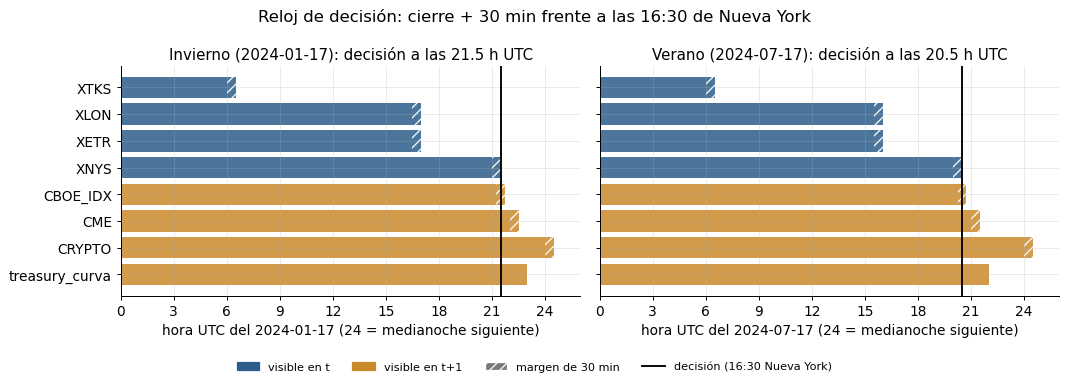

estacion,invierno,verano
dato,,
XTKS,mismo día (t),mismo día (t)
XLON,mismo día (t),mismo día (t)
XETR,mismo día (t),mismo día (t)
XNYS,mismo día (t),mismo día (t)
CBOE_IDX,día siguiente (t+1),día siguiente (t+1)
CME,día siguiente (t+1),día siguiente (t+1)
CRYPTO,día siguiente (t+1),día siguiente (t+1)
treasury_curva,día siguiente (t+1),día siguiente (t+1)


In [3]:
MERCADOS_RELOJ = ['XTKS', 'XLON', 'XETR', 'XNYS', 'CBOE_IDX', 'CME', 'CRYPTO']
DIAS = {'invierno': pd.Timestamp('2024-01-17'), 'verano': pd.Timestamp('2024-07-17')}

def horas_utc(instante, dia):
    return (instante.tz_convert('UTC').tz_localize(None) - dia) / pd.Timedelta(hours=1)

filas = []
for estacion, dia in DIAS.items():
    for m in MERCADOS_RELOJ:
        disp = visibilidad.disponible_cierre(dia, m)
        filas.append({'estacion': estacion, 'dato': m, 'tipo': 'cierre + 30 min', 'disponible_utc': disp,
                      'fecha_publicacion': visibilidad.primera_decision(disp)})
    disp = visibilidad.disponible_publicador('treasury_curva', dia)
    filas.append({'estacion': estacion, 'dato': 'treasury_curva', 'tipo': 'publicación', 'disponible_utc': disp,
                  'fecha_publicacion': visibilidad.primera_decision(disp)})
reloj = pd.DataFrame(filas)
reloj['dia'] = reloj['estacion'].map(DIAS)
reloj['hora_utc'] = [horas_utc(d, dia) for d, dia in zip(reloj['disponible_utc'], reloj['dia'])]
reloj['visible'] = np.where(reloj['fecha_publicacion'] == reloj['dia'], 'mismo día (t)', 'día siguiente (t+1)')

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (estacion, dia) in zip(ejes, DIAS.items()):
    r = reloj[reloj['estacion'] == estacion].reset_index(drop=True)
    decision = horas_utc(visibilidad.momento_decision(dia), dia)
    colores = [C_MISMO if v.startswith('mismo') else C_SIGUIENTE for v in r['visible']]
    ax.barh(r['dato'], r['hora_utc'], color=colores, alpha=0.85)
    margen = np.where(r['tipo'] == 'publicación', 0.0, 0.5)
    ax.barh(r['dato'], margen, left=r['hora_utc'] - margen, facecolor='none', hatch='///',
            edgecolor='white', linewidth=0)
    ax.axvline(decision, color='black', lw=1.5)
    ax.set_xlim(0, 26)
    ax.set_xticks(range(0, 27, 3))
    ax.set_xlabel(f'hora UTC del {dia.date()} (24 = medianoche siguiente)')
    ax.set_title(f'{estacion.capitalize()} ({dia.date()}): decisión a las {decision:.1f} h UTC')
ejes[0].invert_yaxis()
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=C_MISMO, label='visible en t'), Patch(color=C_SIGUIENTE, label='visible en t+1'),
                    Patch(facecolor=C_GRIS, hatch='///', edgecolor='white', label='margen de 30 min'),
                    Line2D([], [], color='black', lw=1.5, label='decisión (16:30 Nueva York)')],
           loc='lower center', ncol=4, frameon=False)
fig.suptitle('Reloj de decisión: cierre + 30 min frente a las 16:30 de Nueva York')
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

display(reloj.pivot(index='dato', columns='estacion', values='visible').loc[MERCADOS_RELOJ + ['treasury_curva']])

## 3. La fuga de Yahoo

Yahoo (y casi cualquier proveedor) publica hoy los precios ajustados con **todos** los splits y
dividendos conocidos hoy. Si un backtest usa esa serie, en cada fecha pasada «sabe» de splits y
dividendos futuros: la escala del precio cambia de golpe en fechas en que nadie podía conocerla.
`ajustar_a_fecha` reconstruye el ajuste con solo los eventos visibles en la fecha de decisión.

Ojo: la fuga está en los **niveles**, no en los retornos. El ajuste multiplicativo solo reescala todo lo
anterior a cada evento, así que el retorno total diario de las sesiones visibles en `t` es el mismo con el
ajuste de `t` y con el de hoy (la cifra está en la salida de la celda siguiente al gráfico). Lo que cambia
es la escala: un umbral de precio, la distancia al máximo histórico, la rentabilidad por dividendo
(dividendo / precio) o la comparación con un precio as-traded de otra fuente usan niveles y sí heredan la fuga.

La acción sintética `ZZAC` tiene cuatro dividendos trimestrales y un split 2:1 el 2023-06-12. Cada fecha
del gráfico conoce un evento más que la anterior: el dividendo del 2022-11-15, el del 2023-02-15 y el split.

,close,dividendo,split
sesion,,,
2022-11-15,96.95,0.8,1.0
2023-02-15,93.30,0.8,1.0
2023-06-12,38.59,0.0,2.0
2023-08-15,47.22,0.4,1.0
2023-11-15,54.82,0.4,1.0


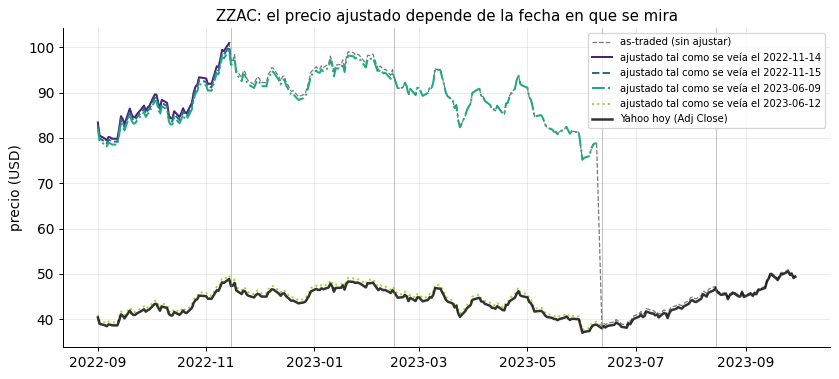

,precio de la sesión 2022-11-01,frente a lo visto el 2022-11-14
visto el 2022-11-14,93.110,+0.00%
visto el 2022-11-15,92.372,-0.79%
visto el 2023-06-09,91.595,-1.63%
visto el 2023-06-12,45.797,-50.81%
Yahoo hoy (Adj Close),45.078,-51.59%
as-traded,93.110,+0.00%


In [4]:
accion = sinteticos.accion_con_eventos()
yahoo = sinteticos.vista_yahoo_hoy(accion)
eventos = accion.loc[(accion['dividendo'] > 0) | (accion['split'] != 1), ['sesion', 'close', 'dividendo', 'split']]
display(eventos.set_index('sesion'))

FECHAS_AJUSTE = ['2022-11-14', '2022-11-15', '2023-06-09', '2023-06-12']
ventana = (pd.Timestamp('2022-09-01'), pd.Timestamp('2023-09-29'))
vistas = {f: timegate.ajustar_a_fecha(accion, f).set_index('sesion') for f in FECHAS_AJUSTE}

fig, ax = plt.subplots(figsize=(11, 4.6))
crudo = accion.set_index('sesion')['close']
ax.plot(crudo.loc[ventana[0]:ventana[1]], color=C_GRIS, lw=1, ls='--', label='as-traded (sin ajustar)')
paleta = plt.cm.viridis(np.linspace(0.1, 0.85, len(FECHAS_AJUSTE)))
estilos = ['-', '--', '-.', ':']
for color, estilo, (f, v) in zip(paleta, estilos, vistas.items()):
    tramo = v.loc[ventana[0]:ventana[1], 'close_aj_total']
    ax.plot(tramo, color=color, lw=1.6, ls=estilo, label=f'ajustado tal como se veía el {f}')
ax.plot(yahoo.loc[ventana[0]:ventana[1], 'Adj Close'], color='black', lw=2, alpha=0.8, label='Yahoo hoy (Adj Close)')
for s in eventos['sesion']:
    if ventana[0] <= s <= ventana[1]:
        ax.axvline(s, color=C_GRIS, lw=0.6, alpha=0.6)
ax.set_title('ZZAC: el precio ajustado depende de la fecha en que se mira')
ax.set_ylabel('precio (USD)')
ax.legend(loc='upper right', fontsize=8)
plt.show()

sesion_ref = pd.Timestamp('2022-11-01')
comparacion = pd.DataFrame({
    'precio de la sesión 2022-11-01': {f'visto el {f}': v.loc[sesion_ref, 'close_aj_total'] for f, v in vistas.items()}
    | {'Yahoo hoy (Adj Close)': yahoo.loc[sesion_ref, 'Adj Close'], 'as-traded': crudo.loc[sesion_ref]}})
comparacion['frente a lo visto el 2022-11-14'] = comparacion.iloc[:, 0] / comparacion.iloc[0, 0] - 1
comparacion['frente a lo visto el 2022-11-14'] = comparacion['frente a lo visto el 2022-11-14'].map('{:+.2%}'.format)
display(comparacion.round(3))

Con la última fecha, el ajuste a fecha coincide con la vista de Yahoo de hoy (diferencia máxima, en la
salida siguiente). El retorno total diario no cambia por el split: el salto del precio as-traded del
2023-06-12 desaparece en `close_aj_total`. Y en cada fecha `t`, los retornos de las sesiones visibles
coinciden con los del `Adj Close` de hoy: la diferencia entre ambos está solo en el nivel.

In [5]:
final = timegate.ajustar_a_fecha(accion, '2024-12-31').set_index('sesion')
print('máx |close_aj_total − Adj Close de Yahoo| :', float(np.abs(final['close_aj_total'] - yahoo['Adj Close']).max()))
print('máx |close_aj_splits − Close de Yahoo|    :', float(np.abs(final['close_aj_splits'] - yahoo['Close']).max()))
ret = final['close_aj_total'].pct_change()
crudo_ret = final['close'].pct_change()
sesion_split = sinteticos.SESION_SPLIT
print(f'retorno del {sesion_split.date()}: as-traded {crudo_ret.loc[sesion_split]:+.2%}, '
      f'ajustado total {ret.loc[sesion_split]:+.2%}')
for t in ['2022-11-14', '2023-06-09']:
    a_fecha = timegate.ajustar_a_fecha(accion, t).set_index('sesion')['close_aj_total']
    hoy = yahoo.loc[a_fecha.index, 'Adj Close']
    dif_ret = float((a_fecha.pct_change() - hoy.pct_change()).abs().max())
    dif_nivel = float((hoy / a_fecha - 1).abs().max())
    print(f'visto el {t}: máx |Δ retorno diario| frente a Yahoo hoy = {dif_ret:.1e}; '
          f'máx |Δ nivel| = {dif_nivel:.2%}')

máx |close_aj_total − Adj Close de Yahoo| : 7.105427357601002e-15
máx |close_aj_splits − Close de Yahoo|    : 0.0
retorno del 2023-06-12: as-traded -51.05%, ajustado total -2.09%
visto el 2022-11-14: máx |Δ retorno diario| frente a Yahoo hoy = 2.2e-16; máx |Δ nivel| = 51.59%
visto el 2023-06-09: máx |Δ retorno diario| frente a Yahoo hoy = 2.2e-16; máx |Δ nivel| = 50.79%


## 4. Vintages

`sint:PARO` imita la tasa de paro de EE. UU. (encuesta de hogares): el informe del mes `m` sale el primer
viernes de `m+1` a las 08:30 de Nueva York con la primera estimación de `m`, y **no** se revisa mes a mes.
La única revisión es la anual de factores estacionales, que llega con el informe de enero (principios de
febrero) y reescribe los cinco años anteriores. Septiembre de 2025 se publica tarde (cierre del Gobierno),
octubre de 2025 **nunca** se publica (una fila con valor nulo y nota) y el informe de enero de 2026 sale el
11 de febrero. El mapa de calor muestra cada valor publicado (fila = mes de referencia, columna = informe);
la cruz marca el hueco.

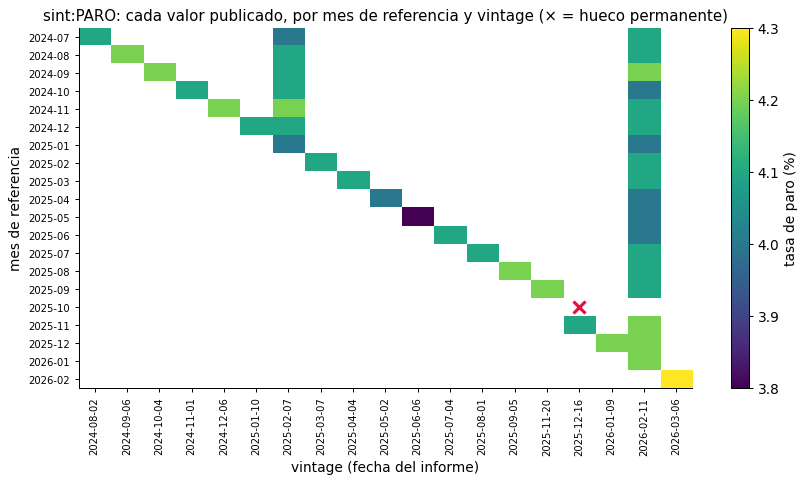

In [6]:
vint = sinteticos.serie_con_vintages()
mapa = vint.pivot(index='fecha_referencia', columns='vintage', values='valor')
desde_mapa = pd.Timestamp('2024-07-01')
mapa = mapa.loc[desde_mapa:, sorted(c for c in mapa.columns if pd.Timestamp(c) >= desde_mapa)]
mapa = mapa.loc[:, mapa.notna().any() | mapa.columns.isin(vint.loc[vint['valor'].isna(), 'vintage'])]

fig, ax = plt.subplots(figsize=(11, 5.2))
im = ax.imshow(np.ma.masked_invalid(mapa.to_numpy()), aspect='auto', cmap='viridis', interpolation='nearest')
ax.set_yticks(range(len(mapa.index)), [d.strftime('%Y-%m') for d in mapa.index], fontsize=8)
ax.set_xticks(range(len(mapa.columns)), mapa.columns, rotation=90, fontsize=8)
hueco = vint[vint['valor'].isna()]
for _, fila in hueco.iterrows():
    if fila['fecha_referencia'] in mapa.index and fila['vintage'] in mapa.columns:
        ax.plot(list(mapa.columns).index(fila['vintage']), list(mapa.index).index(fila['fecha_referencia']),
                marker='x', color='crimson', ms=10, mew=2.5)
ax.set_xlabel('vintage (fecha del informe)')
ax.set_ylabel('mes de referencia')
ax.set_title('sint:PARO: cada valor publicado, por mes de referencia y vintage (× = hueco permanente)')
fig.colorbar(im, ax=ax, label='tasa de paro (%)')
ax.grid(False)
plt.show()

2025-01-15: último periodo 2024-12-01 = 4.1 (publicado el 2025-01-10); avisos: ninguno
2025-11-21: último periodo 2025-09-01 = 4.2 (publicado el 2025-11-20); avisos: ninguno
2026-03-31: último periodo 2026-02-01 = 4.3 (publicado el 2026-03-06); avisos: ['2025-10-01: valor nulo (hueco declarado): hueco permanente: no publicado por el cierre del Gobierno federal (1-oct a 12-nov-2025); la encuesta de hogares de octubre no se recogió']


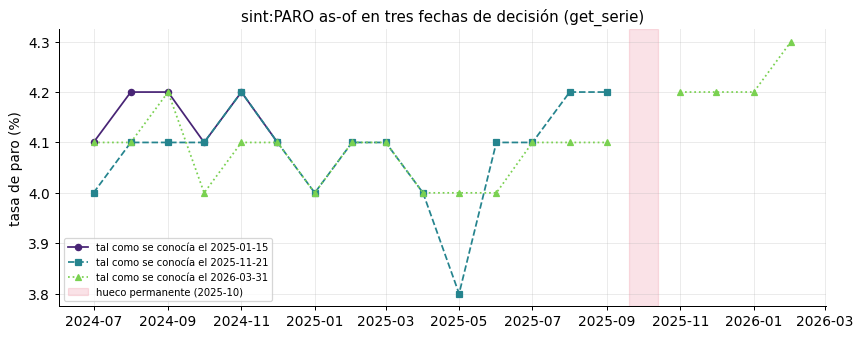

In [7]:
FECHAS_ASOF = ['2025-01-15', '2025-11-21', '2026-03-31']   # antes y después de cada revisión anual
fig, ax = plt.subplots(figsize=(11, 4))
for color, (estilo, marca), f in zip(plt.cm.viridis(np.linspace(0.1, 0.8, len(FECHAS_ASOF))),
                                     [('-', 'o'), ('--', 's'), (':', '^')], FECHAS_ASOF):
    r = tools.get_serie(sinteticos.SERIE_VINTAGES, f, desde='2024-07-01', base=vint)
    d = r.datos.set_index('fecha_referencia')['valor']
    ax.plot(d.index, d.to_numpy(), marker=marca, ms=5, ls=estilo, lw=1.4, color=color,
            label=f'tal como se conocía el {f}')
    print(f'{f}: último periodo {r.ultimo()["fecha_referencia"]} = {r.ultimo()["valor"]} '
          f'(publicado el {r.ultimo()["fecha_publicacion"]}); avisos: {r.avisos or "ninguno"}')
ax.axvspan(sinteticos.MES_HUECO - pd.Timedelta(days=12), sinteticos.MES_HUECO + pd.Timedelta(days=12),
           color='crimson', alpha=0.12, label='hueco permanente (2025-10)')
ax.set_title('sint:PARO as-of en tres fechas de decisión (get_serie)')
ax.set_ylabel('tasa de paro (%)')
ax.legend(fontsize=8)
plt.show()

## 5. Prueba de truncado en directo

La propiedad central del TimeGate: el resultado en la fecha `t` **no cambia** si a la base se le añaden
filas publicadas después de `t` (revisiones, sesiones nuevas, splits y dividendos futuros, fixings del
BCE posteriores). Se compara la base completa con la base truncada a `fecha_publicacion <= t`, en varias
fechas, para series, precios ajustados y precios convertidos a USD. La diferencia máxima debe ser 0.

In [8]:
def truncar(df, t):
    return df[df['fecha_publicacion'] <= pd.Timestamp(t)]

def dif_max(a, b):
    a, b = a.reset_index(drop=True), b.reset_index(drop=True)
    if a.shape != b.shape or list(a.columns) != list(b.columns):
        return np.inf
    num = a.select_dtypes('number').columns
    if not a.drop(columns=num).equals(b.drop(columns=num)):
        return np.inf
    if len(num) == 0:
        return 0.0
    x, y = a[num].to_numpy(float), b[num].to_numpy(float)
    iguales_nan = np.isnan(x) & np.isnan(y)
    return float(np.nanmax(np.where(iguales_nan, 0.0, np.abs(x - y)), initial=0.0))

multi = sinteticos.precios_multimercado()
fx = sinteticos.fx_ecb_sintetico()
comprobaciones = []
for t in ['2023-02-03', '2023-06-09', '2025-10-03', '2025-12-16', '2026-02-06']:
    a = timegate.as_of_series(vint, sinteticos.SERIE_VINTAGES, t)
    b = timegate.as_of_series(truncar(vint, t), sinteticos.SERIE_VINTAGES, t)
    comprobaciones.append(('series: as_of_series sint:PARO', t, len(a), dif_max(a, b)))
for t in ['2022-11-14', '2023-02-15', '2023-06-09', '2023-06-12', '2024-06-28']:
    a = timegate.ajustar_a_fecha(accion, t)
    b = timegate.ajustar_a_fecha(truncar(accion, t), t)
    comprobaciones.append(('precios: ajustar_a_fecha ZZAC', t, len(a), dif_max(a, b)))
    a = tools.get_precios('ZZAC', t, ajuste='total', base=accion).datos
    b = tools.get_precios('ZZAC', t, ajuste='total', base=truncar(accion, t)).datos
    comprobaciones.append(('precios: get_precios ZZAC (total, USD)', t, len(a), dif_max(a, b)))
for t in ['2024-03-06', '2024-03-08', '2024-03-11', '2024-03-15']:
    tk = ['ZZLN.L', '9999.T', 'ZZDE.DE', 'ZZ=F', 'ZZ-USD']
    a = tools.get_precios(tk, t, base=multi, base_fx=fx).datos
    b = tools.get_precios(tk, t, base=truncar(multi, t), base_fx=truncar(fx, t)).datos
    comprobaciones.append(('precios: get_precios multimercado a USD', t, len(a), dif_max(a, b)))

tabla = pd.DataFrame(comprobaciones, columns=['comprobación', 'fecha', 'filas', 'diferencia máxima'])
display(tabla)
assert (tabla['diferencia máxima'] == 0).all(), 'el truncado falla'
print(f'{len(tabla)} comprobaciones; diferencia máxima global = {tabla["diferencia máxima"].max()}')

,comprobación,fecha,filas,diferencia máxima
0,series: as_of_series sint:PARO,2023-02-03,1,0.0
1,series: as_of_series sint:PARO,2023-06-09,5,0.0
2,series: as_of_series sint:PARO,2025-10-03,32,0.0
3,series: as_of_series sint:PARO,2025-12-16,35,0.0
4,series: as_of_series sint:PARO,2026-02-06,36,0.0
5,precios: ajustar_a_fecha ZZAC,2022-11-14,226,0.0
6,"precios: get_precios ZZAC (total, USD)",2022-11-14,226,0.0
7,precios: ajustar_a_fecha ZZAC,2023-02-15,293,0.0
8,"precios: get_precios ZZAC (total, USD)",2023-02-15,293,0.0
9,precios: ajustar_a_fecha ZZAC,2023-06-09,375,0.0


19 comprobaciones; diferencia máxima global = 0.0


## Conclusiones

- El contrato separa **lo que se publicó** (series con vintages; precios as-traded con sus eventos) de
  **cómo se lee** (as-of, ajuste y divisa en el momento de la consulta).
- El reloj fija qué es visible en cada decisión: Asia, Europa y el cierre de Nueva York, el mismo día; el
  VIX, los futuros de CME, la vela cripto y la curva del Tesoro, el día siguiente (tabla de la sección 2).
- El precio ajustado de un proveedor «visto hoy» no es el que se veía en el pasado; la diferencia en
  la sesión de ejemplo aparece en la tabla de la sección 3. Los retornos diarios coinciden: la fuga está
  en los niveles (umbrales, dividendo / precio, comparación con precios as-traded).
- La prueba de truncado da diferencia máxima 0 en todas las comprobaciones de la sección 5.